# Fine-tune lại Qwen2.5-7B-Instruct (LoRA) nhiều epoch để vẽ biểu đồ — Kaggle TPU v5e-8

Giống notebook huấn luyện trước (cùng dữ liệu, cùng cách chia train/val, cùng tham số LoRA), khác ở chỗ:
- Huấn luyện **6 epoch** (đổi `NUM_EPOCHS` nếu muốn), lưu LoRA adapter sau **mỗi** epoch.
- Đánh giá validation **4 lần mỗi epoch** và cuối mỗi epoch, nên có đường validation loss / perplexity mịn để vẽ.
- Ghi toàn bộ log (train loss, val loss, learning rate) ra `log_history.json` sau mỗi lần log,
  để notebook `kaggle_gpu_metrics` đọc lại và vẽ biểu đồ cho bài báo.
- Vẽ sẵn biểu đồ loss và perplexity ngay trong notebook này (`figures/`).

Train nhiều epoch hơn sẽ thấy rõ điểm bắt đầu overfit (validation loss tăng lại); epoch dùng cho hệ thống vẫn
là epoch có validation loss thấp nhất.

**Cài đặt Kaggle**: Accelerator **TPU VM v5e-8**, Internet **On**, Input là dataset chứa
`task3_hoi_thoai_5000_chatml.jsonl` và `task3_hoi_thoai_5000.json`. Chạy bằng **Save Version → Save & Run All**
và tạo notebook MỚI (đừng lưu đè lên modelG101 để không mất adapter cũ).

In [1]:
# Kaggle TPU image có sẵn torch + torch_xla. Không nâng cấp torch/torch_xla để tránh lệch phiên bản libtpu.
!pip uninstall -y transformers huggingface-hub tokenizers
!pip install -q "transformers>=4.45" "peft>=0.13" "accelerate>=1.0" "datasets>=3.0" "huggingface-hub>=1.23.0"

Found existing installation: transformers 5.12.1


Uninstalling transformers-5.12.1:


  Successfully uninstalled transformers-5.12.1


Found existing installation: huggingface_hub 1.33.0


Uninstalling huggingface_hub-1.33.0:


  Successfully uninstalled huggingface_hub-1.33.0


Found existing installation: tokenizers 0.23.0rc0
Uninstalling tokenizers-0.23.0rc0:


  Successfully uninstalled tokenizers-0.23.0rc0


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.37.1 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 2.2.0 which is incompatible.
google-tunix 0.1.8 requires safetensors<0.8, but you have safetensors 0.8.0 which is incompatible.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import os, json, math, random, glob
os.environ.setdefault("PJRT_DEVICE", "TPU")
os.environ.setdefault("XLA_USE_BF16", "0")

import numpy as np
import torch
import torch_xla
import torch_xla.core.xla_model as xm
import torch_xla.runtime as xr

xr.use_spmd()
print("torch", torch.__version__, "| torch_xla", torch_xla.__version__, "| devices", xr.global_runtime_device_count())

from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, TrainerCallback, set_seed
from peft import LoraConfig, get_peft_model
from safetensors.torch import save_file

/usr/local/lib/python3.12/site-packages/torch_xla/experimental/gru.py:113: SyntaxWarning: invalid escape sequence '\_'
  * **h_n**: tensor of shape :math:`(D * \text{num\_layers}, H_{out})` or


/usr/local/lib/python3.12/site-packages/torch_xla/__init__.py:258: UserWarning: `tensorflow` can conflict with `torch-xla`. Prefer `tensorflow-cpu` when using PyTorch/XLA. To silence this warning, `pip uninstall -y tensorflow && pip install tensorflow-cpu`. If you are in a notebook environment such as Colab or Kaggle, restart your notebook runtime afterwards.
  warnings.warn(


torch 2.8.0+cpu | torch_xla 2.8.0 | devices 8


E0000 00:00:1791731688.842505      74 common_lib.cc:648] Could not set metric server port: INVALID_ARGUMENT: Could not find SliceBuilder port 8471 in any of the 0 ports provided in `tpu_process_addresses`="local"
=== Source Location Trace: ===
learning/45eac/tfrc/runtime/common_lib.cc:238


In [3]:
SEED = 42
MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"
NUM_EPOCHS = 6
EVALS_PER_EPOCH = 4
RUN_NAME = f"qwen25-7b-lora-{NUM_EPOCHS}ep"
OUTPUT_DIR = f"/kaggle/working/{RUN_NAME}"
FIG_DIR = "/kaggle/working/figures"
MAX_LEN_CAP = 2048
N_VAL = 200
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"Không tìm thấy {name} trong /kaggle/input"
    return hits[0]

CHATML_PATH = find("task3_hoi_thoai_5000_chatml.jsonl")
META_PATH = find("task3_hoi_thoai_5000.json")
set_seed(SEED)

In [4]:
rows = [json.loads(l) for l in open(CHATML_PATH, encoding="utf-8") if l.strip()]
meta = json.load(open(META_PATH, encoding="utf-8"))
assert len(rows) == len(meta), "chatml và json phải cùng số dòng, cùng thứ tự"
groups = [m["metadata"]["scenario_type"] for m in meta]

# Chia phân tầng theo nhóm A/B/C — giống hệt lần huấn luyện trước
rng = random.Random(SEED)
by_group = {}
for i, g in enumerate(groups):
    by_group.setdefault(g, []).append(i)
val_idx = []
for g, idx in by_group.items():
    rng.shuffle(idx)
    val_idx += idx[: round(N_VAL * len(idx) / len(rows))]
val_set = set(val_idx)
train_rows = [rows[i] for i in range(len(rows)) if i not in val_set]
val_rows = [rows[i] for i in sorted(val_set)]
print("train", len(train_rows), "| val", len(val_rows))

train 4228 | val 200


In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = "<|endoftext|>"

if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.convert_tokens_to_ids("<|endoftext|>")

def encode(messages):
    """Token hóa chuẩn cho Qwen: ghép token IDs trực tiếp, không bao giờ lệch nhãn."""
    # 1. Tạo prompt text (đến hết header của assistant)
    prompt_text = tokenizer.apply_chat_template(
        messages[:-1], tokenize=False, add_generation_prompt=True
    )
    prompt_ids = tokenizer.encode(prompt_text, add_special_tokens=False)

    # 2. Tạo response text của assistant (kèm token kết thúc turn <|im_end|>\n)
    assistant_content = messages[-1]["content"]
    # Thêm token kết thúc theo đúng chuẩn ChatML của Qwen
    response_text = assistant_content + "<|im_end|>\n"
    response_ids = tokenizer.encode(response_text, add_special_tokens=False)

    # 3. Ghép IDs: prompt + response
    full_ids = prompt_ids + response_ids

    # 4. Mask nhãn: toàn bộ prompt là -100, chỉ tính loss trên response
    labels = [-100] * len(prompt_ids) + response_ids

    return full_ids, labels

enc_train = [encode(r["messages"]) for r in train_rows]
enc_val = [encode(r["messages"]) for r in val_rows]
lens = [len(ids) for ids, _ in enc_train + enc_val]

print("token length: max", max(lens), "| p99", int(np.percentile(lens, 99)), "| median", int(np.median(lens)))
MAX_LEN = min(MAX_LEN_CAP, int(math.ceil(max(lens) / 128) * 128))
print("MAX_LEN =", MAX_LEN)

def to_dataset(encoded):
    data = {"input_ids": [], "attention_mask": [], "labels": []}
    for ids, labels in encoded:
        if len(ids) > MAX_LEN:
            continue
        pad = MAX_LEN - len(ids)
        data["input_ids"].append(ids + [tokenizer.pad_token_id] * pad)
        data["attention_mask"].append([1] * len(ids) + [0] * pad)
        data["labels"].append(labels + [-100] * pad)
    return Dataset.from_dict(data).with_format("torch")

train_ds = to_dataset(enc_train)
val_ds = to_dataset(enc_val)

BATCH = 8
steps_per_epoch = len(train_ds) // BATCH
EVAL_STEPS = max(1, steps_per_epoch // EVALS_PER_EPOCH)
print("steps/epoch", steps_per_epoch, "| eval mỗi", EVAL_STEPS, "bước | tổng", steps_per_epoch * NUM_EPOCHS, "bước")

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

token length: max 475 | p99 419 | median 303
MAX_LEN = 512


steps/epoch 528 | eval mỗi 132 bước | tổng 3168 bước


In [6]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, 
    torch_dtype=torch.bfloat16, 
    low_cpu_mem_usage=True
)

model.config.use_cache = False

model.enable_input_require_grads()

lora_config = LoraConfig(
    r=16, 
    lora_alpha=32, 
    lora_dropout=0.0,  
    bias="none", 
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)

model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


In [7]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=BATCH,    # SPMD FSDPv2: batch toàn cục, chia hết cho 8 chip
    per_device_eval_batch_size=BATCH,
    gradient_accumulation_steps=1,
    num_train_epochs=NUM_EPOCHS,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=int(steps_per_epoch * NUM_EPOCHS * 0.05),  # Dùng warmup_steps thay cho warmup_ratio
    weight_decay=0.01,
    optim="adamw_torch",
    bf16=True,
    seed=SEED,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=EVAL_STEPS,
    save_strategy="no",                   # Tự lưu LoRA bằng callback để không đầy ổ đĩa 15GB
    dataloader_drop_last=True,
    remove_unused_columns=False,
    report_to="none",
    fsdp="full_shard",
    fsdp_config={
        "transformer_layer_cls_to_wrap": ["Qwen2DecoderLayer"],
        "xla": True,
        "xla_fsdp_v2": True,
        "xla_fsdp_grad_ckpt": True,
    },
)

class XLAFSDPTrainer(Trainer):
    def create_scheduler(self, num_training_steps: int, optimizer: torch.optim.Optimizer = None):
        if self.optimizer is None:
            self.create_optimizer()
            self.optimizer = self.accelerator.prepare(self.optimizer)
        return super().create_scheduler(num_training_steps=num_training_steps, optimizer=self.optimizer)
        
peft_model = model
def save_lora(out_dir):
    """Gom các tham số LoRA (đang chia trên 8 chip) về CPU và lưu theo định dạng PEFT adapter."""
    xm.mark_step()
    state = {}
    target_model = trainer.model if 'trainer' in globals() and hasattr(trainer, "model") else peft_model
    for name, param in target_model.named_parameters():
        if not param.requires_grad:
            continue
        for wrapper in ("_orig_module.", "_fsdp_wrapped_module.", "_checkpoint_wrapped_module."):
            name = name.replace(wrapper, "")
        name = name.replace(".default.", ".")
        state[name] = param.detach().to("cpu").contiguous()
    
    if xm.is_master_ordinal():
        os.makedirs(out_dir, exist_ok=True)
        save_file(state, os.path.join(out_dir, "adapter_model.safetensors"))
        peft_model.peft_config["default"].save_pretrained(out_dir)
        tokenizer.save_pretrained(out_dir)
        print(f"\n[Saved] Đã lưu {len(state)} LoRA tensors -> {out_dir}")
LOG_PATH = os.path.join(OUTPUT_DIR, "log_history.json")

class EpochCallback(TrainerCallback):
    def on_epoch_end(self, args, state, control, **kwargs):
        save_lora(os.path.join(OUTPUT_DIR, f"epoch-{round(state.epoch)}"))
        if state.global_step % EVAL_STEPS != 0:
            control.should_evaluate = True    # Luôn có một điểm validation đúng cuối mỗi epoch
        return control
    def on_log(self, args, state, control, **kwargs):
        if xm.is_master_ordinal():
            with open(LOG_PATH, "w", encoding="utf-8") as f:
                json.dump(state.log_history, f, ensure_ascii=False, indent=1)

trainer = XLAFSDPTrainer(
    model=model, 
    args=training_args, 
    train_dataset=train_ds, 
    eval_dataset=val_ds,
    callbacks=[EpochCallback()]
)

[transformers] Passing `fsdp` as a string is deprecated and will be removed in Transformers v5.20. Use `fsdp=True` and configure everything via `fsdp_config` instead.


In [8]:
# Bắt đầu huấn luyện trực tiếp
trainer.train()

# Ghi lại log hoàn chỉnh
with open(LOG_PATH, "w", encoding="utf-8") as f:
    json.dump(trainer.state.log_history, f, ensure_ascii=False, indent=1)

/usr/local/lib/python3.12/site-packages/jax/_src/cloud_tpu_init.py:88: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


/usr/local/lib/python3.12/site-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


/usr/local/lib/python3.12/site-packages/torch/nn/modules/module.py:1847: UserWarning: For backward hooks to be called, module output should be a Tensor or a tuple of Tensors but received <class 'transformers.modeling_outputs.CausalLMOutputWithPast'>
  warnings.warn("For backward hooks to be called,"


Step,Training Loss,Validation Loss
132,0.881250,0.894063
264,0.771875,0.789844
396,0.768750,0.744844
528,0.703125,0.720625
660,0.656250,0.714688
792,0.631250,0.706406
924,0.628125,0.696719
1056,0.615625,0.681875
1188,0.481250,0.717031
1320,0.496875,0.711563


/tmp/ipykernel_74/349578155.py:40: DeprecationWarning: Use torch_xla.sync instead
  xm.mark_step()


...


[Saved] Đã lưu 392 LoRA tensors -> /kaggle/working/qwen25-7b-lora-6ep/epoch-2



[Saved] Đã lưu 392 LoRA tensors -> /kaggle/working/qwen25-7b-lora-6ep/epoch-3



[Saved] Đã lưu 392 LoRA tensors -> /kaggle/working/qwen25-7b-lora-6ep/epoch-4



[Saved] Đã lưu 392 LoRA tensors -> /kaggle/working/qwen25-7b-lora-6ep/epoch-5



[Saved] Đã lưu 392 LoRA tensors -> /kaggle/working/qwen25-7b-lora-6ep/epoch-6


In [9]:
# Validation loss / perplexity cuối mỗi epoch và epoch tốt nhất
log = trainer.state.log_history
epoch_end = {}
for h in log:
    if "eval_loss" in h and abs(h["epoch"] - round(h["epoch"])) < 0.05:
        epoch_end[round(h["epoch"])] = h["eval_loss"]
        
print("--- KẾT QUẢ ĐÁNH GIÁ TỪNG EPOCH ---")
for e, l in sorted(epoch_end.items()):
    print(f"Epoch {e}: val_loss {l:.4f} | perplexity {math.exp(l):.3f}")

if epoch_end:
    best_epoch = min(epoch_end, key=epoch_end.get)
    print(f"\n=> Epoch tốt nhất (Val Loss thấp nhất): Epoch {best_epoch}")
    with open(os.path.join(OUTPUT_DIR, "summary.json"), "w", encoding="utf-8") as f:
        json.dump({"best_epoch": best_epoch, "epoch_val_loss": epoch_end}, f, indent=1)
print("\nDanh sách tệp đã lưu trong thư mục đầu ra:")
print(sorted(os.listdir(OUTPUT_DIR)))

--- KẾT QUẢ ĐÁNH GIÁ TỪNG EPOCH ---
Epoch 1: val_loss 0.7206 | perplexity 2.056
Epoch 2: val_loss 0.6819 | perplexity 1.978
Epoch 3: val_loss 0.7053 | perplexity 2.024
Epoch 4: val_loss 0.7781 | perplexity 2.177
Epoch 5: val_loss 0.8989 | perplexity 2.457
Epoch 6: val_loss 0.9413 | perplexity 2.563

=> Epoch tốt nhất (Val Loss thấp nhất): Epoch 2

Danh sách tệp đã lưu trong thư mục đầu ra:
['epoch-1', 'epoch-2', 'epoch-3', 'epoch-4', 'epoch-5', 'epoch-6', 'log_history.json', 'summary.json']


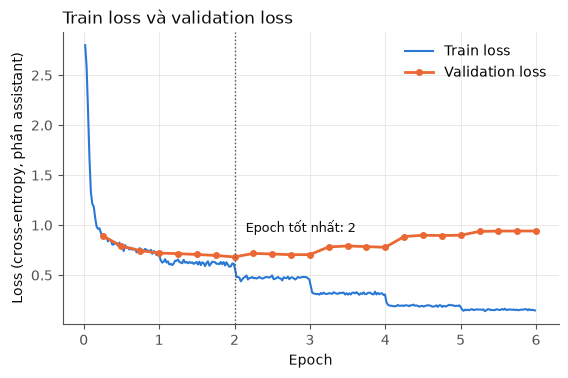

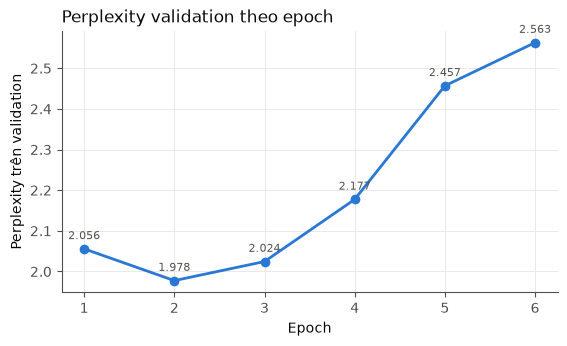

In [10]:
# Biểu đồ loss và perplexity cho bài báo (PNG 300 dpi + PDF vector)
import matplotlib.pyplot as plt

LANG = "vi"   # "en" nếu bài viết bằng tiếng Anh
TXT = {
    "vi": {
        "step": "Epoch", "loss": "Loss (cross-entropy, phần assistant)", "train": "Train loss",
        "val": "Validation loss", "best": "Epoch tốt nhất", "ppl": "Perplexity trên validation",
        "ppl_t": "Perplexity validation theo epoch", "loss_t": "Train loss và validation loss"
    },
    "en": {
        "step": "Epoch", "loss": "Loss (cross-entropy, assistant tokens)", "train": "Train loss",
        "val": "Validation loss", "best": "Best epoch", "ppl": "Validation perplexity",
        "ppl_t": "Validation perplexity by epoch", "loss_t": "Training and validation loss"
    },
}[LANG]
BLUE, ORANGE = "#2a78d6", "#eb6834"         # slot 1-2 của bảng màu categorical đã kiểm định
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "legend.frameon": False,
    "savefig.dpi": 300, "savefig.bbox": "tight", "figure.facecolor": "white",
})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))
    plt.show()

tr = [(h["epoch"], h["loss"]) for h in log if "loss" in h and "eval_loss" not in h]
ev = [(h["epoch"], h["eval_loss"]) for h in log if "eval_loss" in h]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(*zip(*tr), color=BLUE, lw=1.5, label=TXT["train"])
ax.plot(*zip(*ev), color=ORANGE, lw=2, marker="o", ms=4, label=TXT["val"])
ax.axvline(best_epoch, color=INK2, ls=":", lw=1)
ax.annotate(f"{TXT['best']}: {best_epoch}", (best_epoch, epoch_end[best_epoch]), xytext=(8, 18),
            textcoords="offset points", color=INK, fontsize=9)
ax.set_xlabel(TXT["step"]); ax.set_ylabel(TXT["loss"]); ax.set_title(TXT["loss_t"], loc="left", color=INK)
ax.set_xticks(range(0, NUM_EPOCHS + 1))
ax.legend(loc="upper right")
save(fig, "loss_curves")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
xs = sorted(epoch_end)
ax.plot(xs, [math.exp(epoch_end[e]) for e in xs], color=BLUE, lw=2, marker="o", ms=6)
for e in xs:
    ax.annotate(f"{math.exp(epoch_end[e]):.3f}", (e, math.exp(epoch_end[e])), xytext=(0, 7),
                textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.set_xlabel(TXT["step"]); ax.set_ylabel(TXT["ppl"]); ax.set_title(TXT["ppl_t"], loc="left", color=INK)
ax.set_xticks(xs)
save(fig, "val_perplexity")

In [11]:
# Nén adapter + log + biểu đồ để tải về (Kaggle không có lệnh zip)
import shutil
print(shutil.make_archive(f"/kaggle/working/{RUN_NAME}", "zip", "/kaggle/working", RUN_NAME))
print(shutil.make_archive("/kaggle/working/figures", "zip", "/kaggle/working", "figures"))

/kaggle/working/qwen25-7b-lora-6ep.zip
/kaggle/working/figures.zip
